# Phase 0: Environment Setup & Data Ingestion

In [ ]:
!pip install shap

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import xgboost as xgb
import shap
import gc


from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout, concatenate, BatchNormalization
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_curve, auc
from tensorflow.keras.utils import plot_model
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

from imblearn.over_sampling import SMOTE
from google.colab import drive

warnings.filterwarnings('ignore')



In [ ]:
import os
import glob
import pandas as pd
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

base_path = '/content/drive/MyDrive/wind_turbine_care/data/farm_a'
all_files = sorted(glob.glob(os.path.join(base_path, '*.csv')))

assert len(all_files) > 0, f"Path not accessible: {os.listdir('/content/drive/MyDrive')}"

dfs = [pd.read_csv(f, sep=';') for f in all_files]
raw_data = pd.concat(dfs, ignore_index=True)

Mounted at /content/drive


In [ ]:
base_path = '/content/drive/MyDrive/wind_turbine_care/data/farm_a'
file_pattern = os.path.join(base_path, '*.csv')
all_files = glob.glob(file_pattern)

dfs = []
for f in all_files:
    df = pd.read_csv(f, sep=';')
    dfs.append(df)

raw_data = pd.concat(dfs, ignore_index=True)

time_col = 'time_stamp' if 'time_stamp' in raw_data.columns else 'time'
sort_cols = []

if 'asset_id' in raw_data.columns:
    sort_cols.append('asset_id')
elif 'id' in raw_data.columns:
    sort_cols.append('id')

sort_cols.append(time_col)

raw_data.sort_values(by=sort_cols, inplace=True)
raw_data.reset_index(drop=True, inplace=True)

split_idx = int(len(raw_data) * 0.8)
train_df = raw_data.iloc[:split_idx].copy()
test_df = raw_data.iloc[split_idx:].copy()

print(f"Loaded {len(dfs)} CSV files ({len(raw_data):,} rows, {len(raw_data.columns)} columns)")
print(f"Train: {len(train_df):,} rows | Test: {len(test_df):,} rows")

Loaded 22 CSV files (1,196,747 rows, 86 columns)
Train: 957,397 rows | Test: 239,350 rows


# Phase 1: Chronological Train-Test Partitioning
Splits the dataset chronologically (80% train, 20% test) rather than randomly. Random shuffling leaks future sensor states into the training set and artificially inflates fault-detection scores on time-series telemetry.

In [ ]:
output_path = '/content/drive/MyDrive/wind_turbine_care/outputs'
os.makedirs(output_path, exist_ok=True)

train_df.to_csv(os.path.join(output_path, 'train_data_split.csv'), index=False)
test_df.to_csv(os.path.join(output_path, 'test_data_split.csv'), index=False)

In [ ]:
file_pattern = os.path.join(base_path, '*.csv')
all_files = glob.glob(file_pattern)

dfs = []
for f in all_files:
    df = pd.read_csv(f, sep=';')
    dfs.append(df)

if not dfs:
    raise ValueError("No CSV files found. Please verify the base_path directory.")

raw_data = pd.concat(dfs, ignore_index=True)

time_col = 'time_stamp' if 'time_stamp' in raw_data.columns else 'time'
id_col = 'asset_id' if 'asset_id' in raw_data.columns else 'id'

raw_data.sort_values(by=[id_col, time_col], inplace=True)
raw_data.reset_index(drop=True, inplace=True)

split_idx = int(len(raw_data) * 0.8)
train_df = raw_data.iloc[:split_idx].copy()
test_df = raw_data.iloc[split_idx:].copy()

train_df.to_csv(os.path.join(output_path, 'train_data_split.csv'), index=False)
test_df.to_csv(os.path.join(output_path, 'test_data_split.csv'), index=False)

print(f"Exported train ({len(train_df):,}) and test ({len(test_df):,}) splits to {output_path}")

Exported train (957,397) and test (239,350) splits to /content/drive/MyDrive/wind_turbine_care/outputs


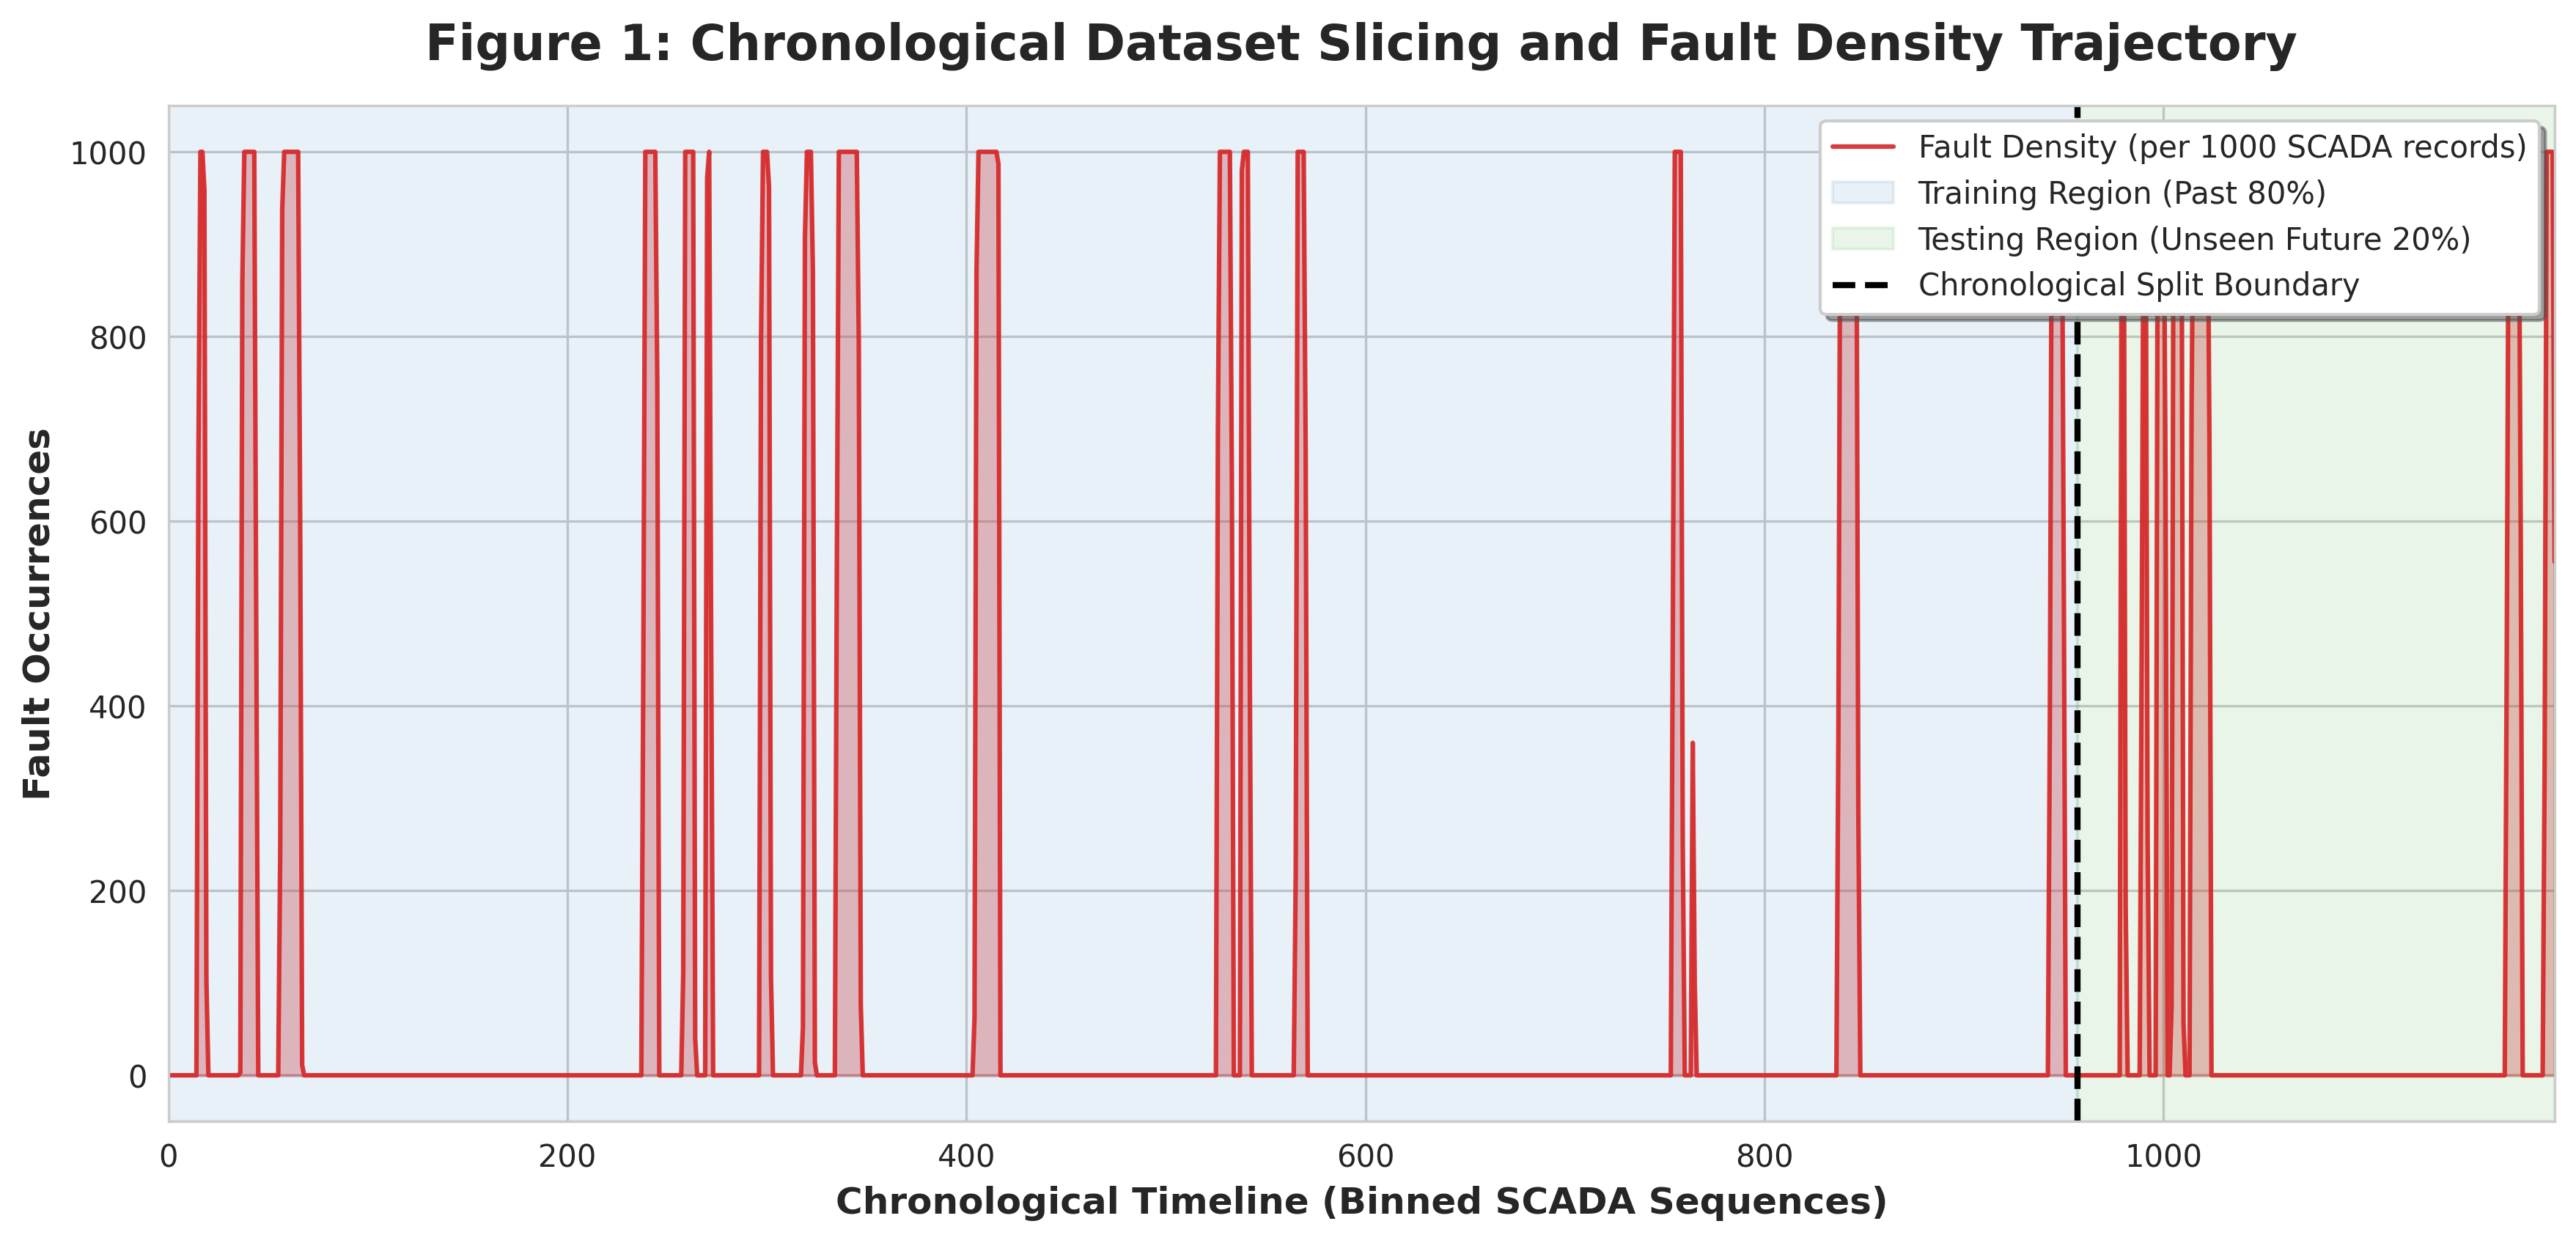

Saved Fig 1 -> /content/drive/MyDrive/wind_turbine_care/outputs/fig1_chronological_split.png


In [ ]:
plot_df = raw_data[['status_type_id']].copy()

plot_df['is_fault'] = plot_df['status_type_id'].apply(lambda x: 0 if x in [0, 5] else 1)

bin_size = 1000
plot_df['time_bin'] = plot_df.index // bin_size
binned_data = plot_df.groupby('time_bin')['is_fault'].sum()

split_bin = split_idx // bin_size

plt.figure(figsize=(14, 6), dpi=300)
sns.set_style("whitegrid")

plt.plot(binned_data.index, binned_data.values, color='#d62728', alpha=0.9, linewidth=1.5, label='Fault Density (per 1000 SCADA records)')
plt.fill_between(binned_data.index, binned_data.values, color='#d62728', alpha=0.3)

plt.axvspan(0, split_bin, color='#1f77b4', alpha=0.1, label='Training Region (Past 80%)')
plt.axvspan(split_bin, binned_data.index.max(), color='#2ca02c', alpha=0.1, label='Testing Region (Unseen Future 20%)')

plt.axvline(x=split_bin, color='black', linestyle='--', linewidth=2, label='Chronological Split Boundary')

plt.title('Figure 1: Chronological Dataset Slicing and Fault Density Trajectory', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Chronological Timeline (Binned SCADA Sequences)', fontsize=12, fontweight='bold')
plt.ylabel('Fault Occurrences', fontsize=12, fontweight='bold')
plt.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
plt.margins(x=0)

img_path = os.path.join(output_path, 'fig1_chronological_split.png')
plt.savefig(img_path, bbox_inches='tight')
plt.show()
plt.close()

del plot_df, binned_data
gc.collect()

print(f"Saved Fig 1 -> {img_path}")

# Phase 2: Exploratory Data Analysis & Degradation Diagnostics
Audits missing sensor values, feature scales, and class imbalance to verify why raw accuracy is a misleading metric here. Plots pre-fault rolling sensor trajectories to confirm measurable physical drift prior to turbine failure.


Class distribution (train):
Normal Operation (0): 88.81%
Faults/Anomalies (1): 11.19%


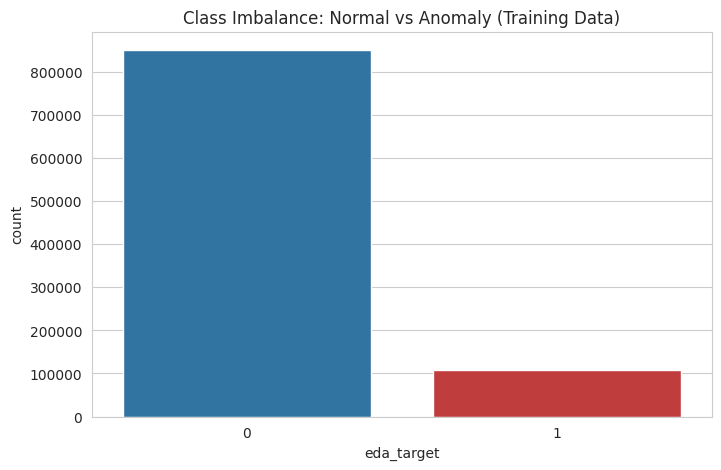


Sensor mean check:
sensor_40_avg Mean: 72.29 hPa

Missing values:
Found 2 columns with missing data.
sensor_14_avg    16
sensor_22_avg    16
dtype: int64

Top 10 features correlated with target:
sensor_5_avg     0.185810
sensor_5_min     0.180575
sensor_0_avg     0.170444
sensor_5_max     0.160812
sensor_41_avg    0.160466
sensor_53_avg    0.152031
sensor_43_avg    0.149144
sensor_14_avg    0.121847
sensor_6_avg     0.119004
sensor_19_avg    0.110008
Name: eda_target, dtype: float64

EDA finished.


In [ ]:
print("Class distribution (train):")
eda_df = train_df.copy()

eda_df['eda_target'] = eda_df['status_type_id'].apply(lambda x: 0 if x in [0, 5] else 1)
class_counts = eda_df['eda_target'].value_counts(normalize=True) * 100

print(f"Normal Operation (0): {class_counts.get(0, 0):.2f}%")
print(f"Faults/Anomalies (1): {class_counts.get(1, 0):.2f}%")

plt.figure(figsize=(8, 5))
sns.countplot(data=eda_df, x='eda_target', hue='eda_target', palette=['#1f77b4', '#d62728'], legend=False)
plt.title('Class Imbalance: Normal vs Anomaly (Training Data)')
plt.savefig(os.path.join(output_path, 'class_imbalance.png'), bbox_inches='tight')
plt.show()
plt.close()

print("\nSensor mean check:")
v6_sensors = ['sensor_40_avg', 'sensor_61_avg']
for sensor in v6_sensors:
    if sensor in eda_df.columns:
        print(f"{sensor} Mean: {eda_df[sensor].mean():.2f} hPa")

print("\nMissing values:")
missing_data = eda_df.isnull().sum()
missing_cols = missing_data[missing_data > 0]
if not missing_cols.empty:
    print(f"Found {len(missing_cols)} columns with missing data.")
    print(missing_cols)
else:
    print("No missing values found.")

print("\nTop 10 features correlated with target:")
numeric_cols = eda_df.select_dtypes(include=[np.number]).columns
correlations = eda_df[numeric_cols].corr()['eda_target'].drop(
    ['eda_target', 'status_type_id', id_col], errors='ignore'
)
top_10_corr = correlations.abs().sort_values(ascending=False).head(10)
print(top_10_corr)

del eda_df
import gc
gc.collect()
print("\nEDA finished.")

Top correlated sensor: sensor_5_avg (turbine 0)


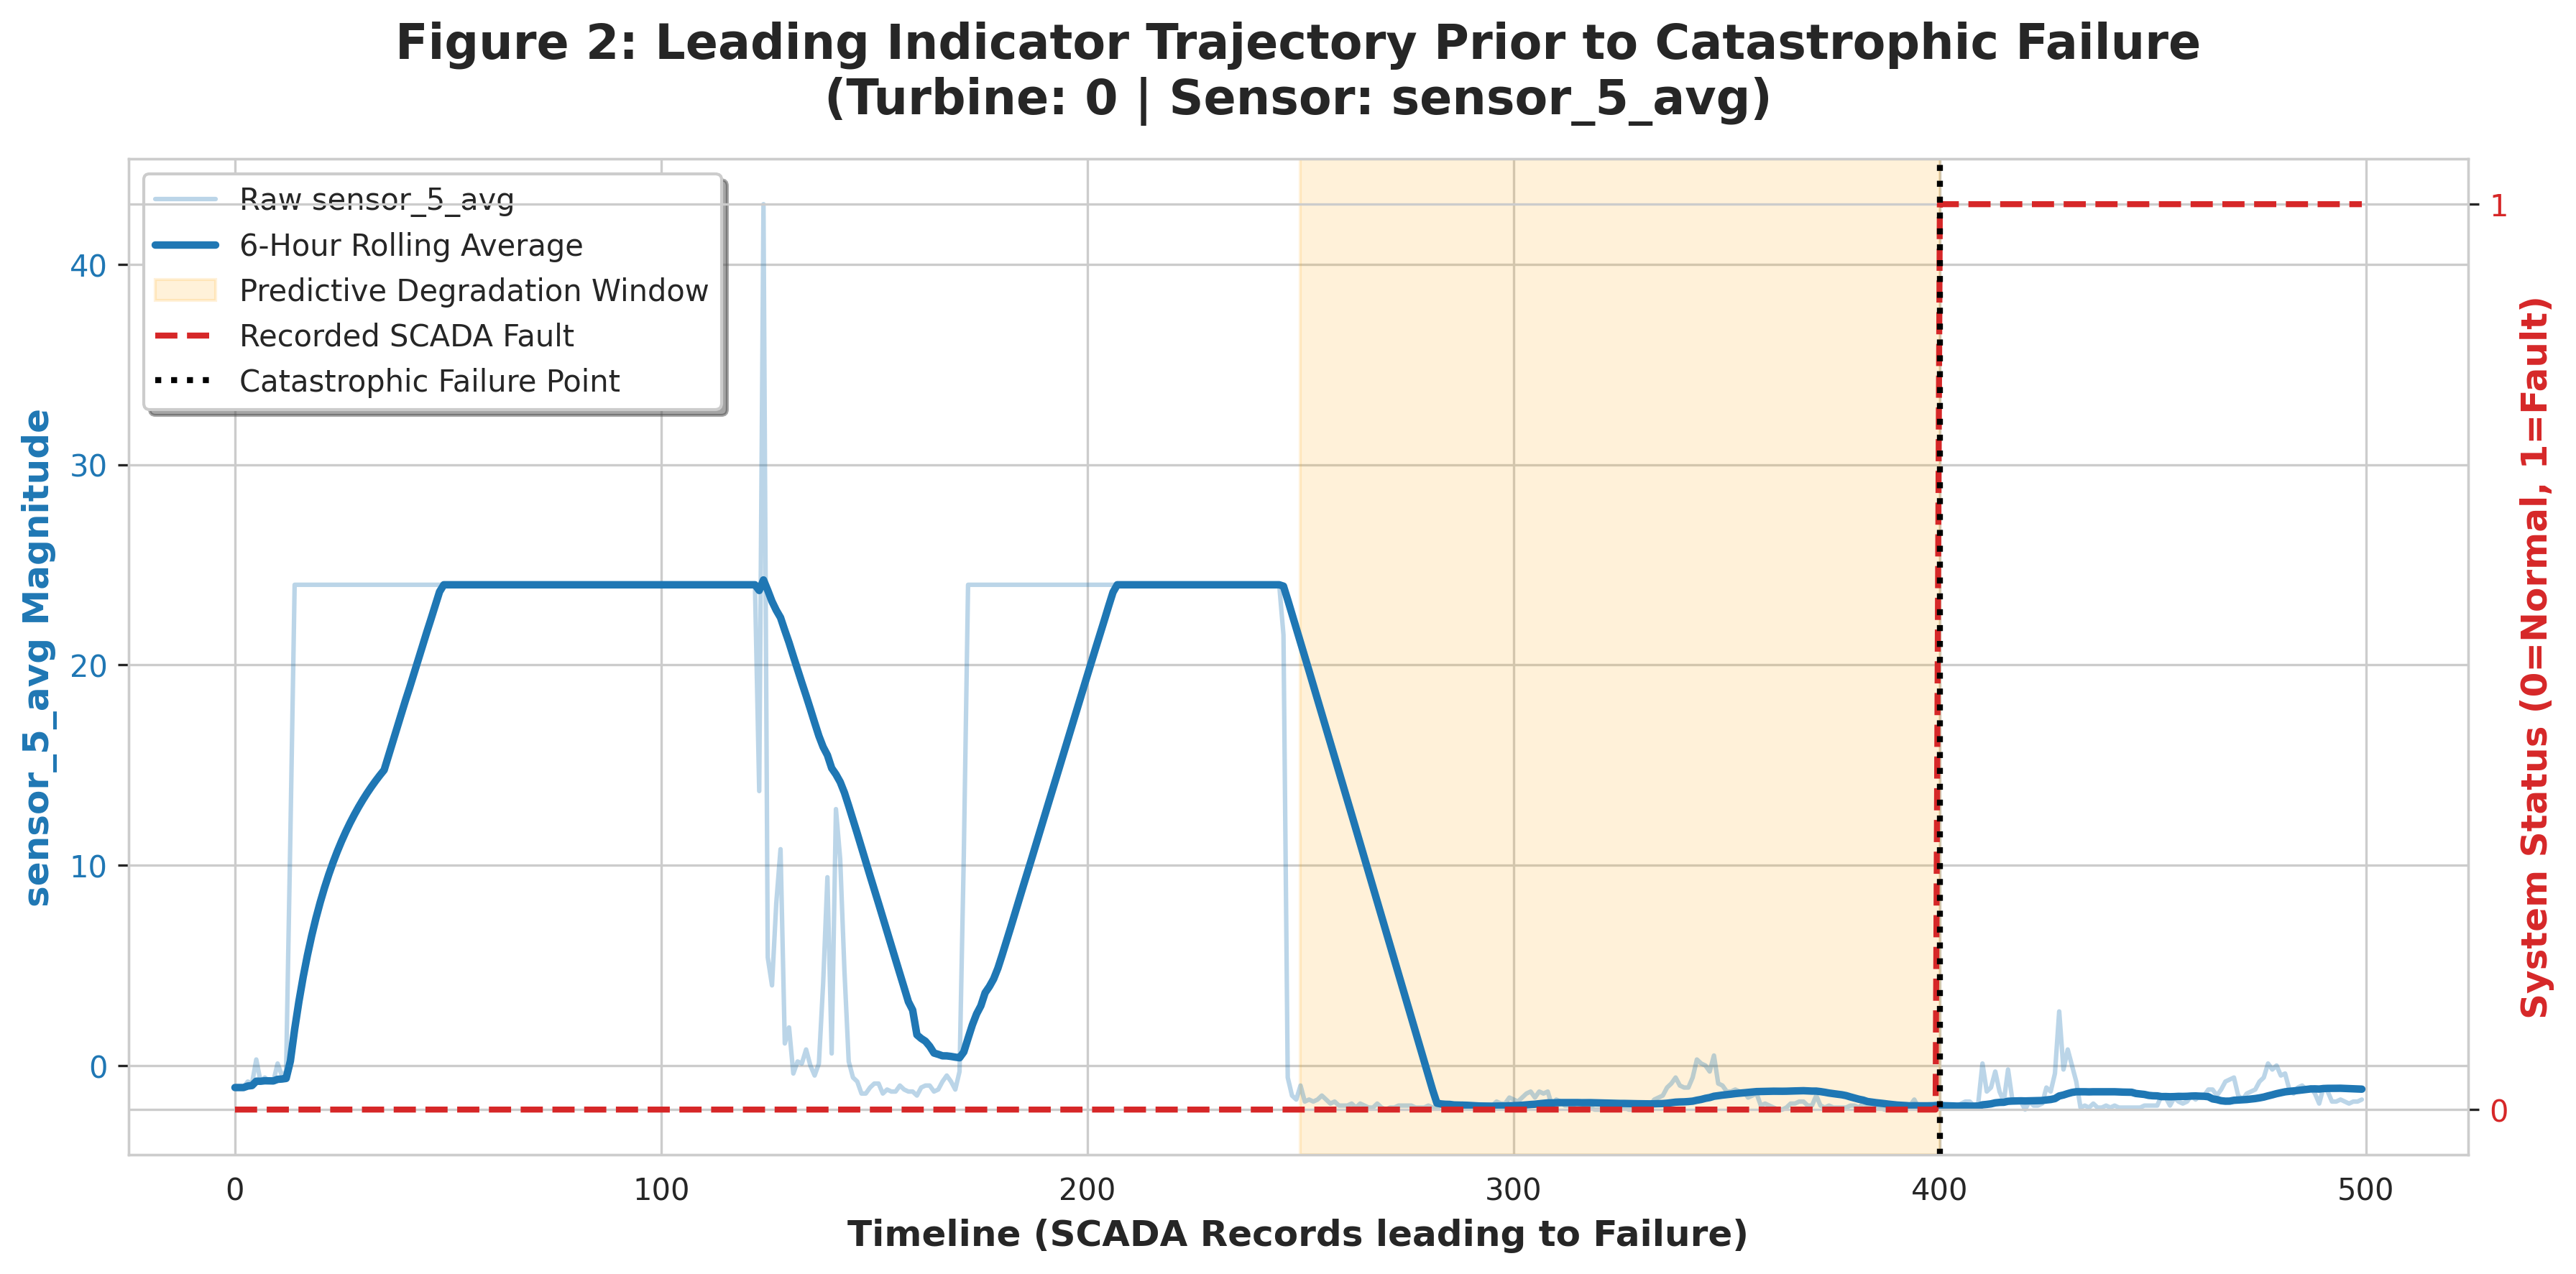

Saved Fig 2 -> /content/drive/MyDrive/wind_turbine_care/outputs/fig2_fault_trajectory.png


In [ ]:
if 'target' in train_df.columns:
    temp_target = train_df['target']
elif 'status_type_id' in train_df.columns:
    temp_target = train_df['status_type_id'].apply(lambda x: 0 if x in [0, 5] else 1)
else:
    raise ValueError("Target column not found. Please re-run Phase 1.")

numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_series = train_df[numeric_cols].corrwith(temp_target).abs()

safe_cols = [c for c in corr_series.index if c not in ['status_type_id', 'target', 'asset_id', 'id', 'time_stamp', 'time', 'is_fault']]
top_sensor = corr_series[safe_cols].idxmax()


plot_df = train_df.copy()
plot_df['is_fault'] = temp_target

id_col_active = 'asset_id' if 'asset_id' in plot_df.columns else 'id'
faulty_turbines = plot_df[plot_df['is_fault'] == 1][id_col_active].unique()

if len(faulty_turbines) == 0:
    target_turbine = plot_df[id_col_active].iloc[0]
else:
    target_turbine = faulty_turbines[0]

print(f"Top correlated sensor: {top_sensor} (turbine {target_turbine})")


turbine_data = plot_df[plot_df[id_col_active] == target_turbine].copy()
turbine_data.reset_index(drop=True, inplace=True)

fault_indices = turbine_data[turbine_data['is_fault'] == 1].index

valid_faults = fault_indices[fault_indices > 400]
if len(valid_faults) > 0:
    fault_idx = valid_faults[0]
    start_idx = fault_idx - 400
    end_idx = fault_idx + 100
elif len(fault_indices) > 0:
    fault_idx = fault_indices[0]
    start_idx = max(0, fault_idx - 400)
    end_idx = min(len(turbine_data), fault_idx + 100)
else:
    fault_idx = len(turbine_data) // 2
    start_idx = max(0, fault_idx - 400)
    end_idx = min(len(turbine_data), fault_idx + 100)

slice_df = turbine_data.iloc[start_idx:end_idx].copy()
slice_df.reset_index(drop=True, inplace=True)

slice_df['sensor_rolling'] = slice_df[top_sensor].rolling(window=36, min_periods=1).mean()

local_faults = slice_df[slice_df['is_fault'] == 1].index
local_fault_idx = local_faults[0] if len(local_faults) > 0 else len(slice_df) // 2

fig, ax1 = plt.subplots(figsize=(14, 6), dpi=300)
sns.set_style("whitegrid")

color1 = '#1f77b4'
ax1.set_xlabel('Timeline (SCADA Records leading to Failure)', fontsize=12, fontweight='bold')
ax1.set_ylabel(f'{top_sensor} Magnitude', color=color1, fontsize=12, fontweight='bold')
ax1.plot(slice_df.index, slice_df[top_sensor], color=color1, alpha=0.3, label=f'Raw {top_sensor}')
ax1.plot(slice_df.index, slice_df['sensor_rolling'], color=color1, linewidth=2.5, label='6-Hour Rolling Average')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('System Status (0=Normal, 1=Fault)', color=color2, fontsize=12, fontweight='bold')
ax2.plot(slice_df.index, slice_df['is_fault'], color=color2, linewidth=2, linestyle='--', label='Recorded SCADA Fault')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_yticks([0, 1])

degradation_start = max(0, local_fault_idx - 150)
ax1.axvspan(degradation_start, local_fault_idx, color='orange', alpha=0.15, label='Predictive Degradation Window')
plt.axvline(x=local_fault_idx, color='black', linestyle=':', linewidth=2, label='Catastrophic Failure Point')

plt.title(f'Figure 2: Leading Indicator Trajectory Prior to Catastrophic Failure\n(Turbine: {target_turbine} | Sensor: {top_sensor})', fontsize=16, fontweight='bold', pad=15)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True, shadow=True, fontsize=10)

plt.margins(x=0)

img_path2 = os.path.join(output_path, 'fig2_fault_trajectory.png')
plt.savefig(img_path2, bbox_inches='tight')
plt.show()
plt.close()

del plot_df, turbine_data, slice_df
gc.collect()

print(f"Saved Fig 2 -> {img_path2}")

# Phase 3: SCADA Preprocessing & Circular Feature Encoding
Imputes missing sensor readings and converts cyclical wind and nacelle angles into $\sin(\theta)$ and $\cos(\theta)$ components. This removes the artificial jump between $0^\circ$ and $360^\circ$ before neural network ingestion.

In [ ]:
print("Initializing Phase 3: V6 Preprocessing...")

metadata_path = '/content/drive/MyDrive/wind_turbine_care/data/metadata'
feature_desc_file = os.path.join(metadata_path, 'feature_description.csv')

angle_cols = []
if os.path.exists(feature_desc_file):
    try:
        feat_desc = pd.read_csv(feature_desc_file, sep=';')
        if 'is_angle' in feat_desc.columns and 'feature_name' in feat_desc.columns:
            angle_cols = feat_desc[feat_desc['is_angle'] == 1]['feature_name'].tolist()
    except Exception:
        pass

if not angle_cols:
    angle_cols = [col for col in train_df.columns if any(s in col for s in ['sensor_1', 'sensor_2', 'sensor_5', 'sensor_42'])]

def preprocess_data(df, angles):
    df_processed = df.copy()

    missing_count = df_processed.isnull().sum().sum()
    if missing_count > 0:
        df_processed.ffill(inplace=True)
        df_processed.bfill(inplace=True)

    if 'status_type_id' in df_processed.columns:
        df_processed['target'] = df_processed['status_type_id'].apply(lambda x: 0 if x in [0, 5] else 1)
        df_processed.drop(columns=['status_type_id'], inplace=True)

    transformed_count = 0
    for col in angles:
        if col in df_processed.columns and 'std' not in col:
            df_processed[f'{col}_sin'] = np.sin(df_processed[col] * np.pi / 180.0)
            df_processed[f'{col}_cos'] = np.cos(df_processed[col] * np.pi / 180.0)
            df_processed.drop(columns=[col], inplace=True)
            transformed_count += 1

    drop_cols = ['id', 'train_test']
    dropped = [c for c in drop_cols if c in df_processed.columns]
    if dropped:
        df_processed.drop(columns=dropped, inplace=True)

    return df_processed, missing_count, transformed_count, dropped

print("--- Processing Training Set ---")
train_df, train_missing, train_transformed, train_dropped = preprocess_data(train_df, angle_cols)
print(f"-> Imputing {train_missing} missing values using Time-Aware Forward-Fill...")
print(f"-> Applied Sine/Cosine transformations to {train_transformed} circular features.")
print(f"-> 'target' column generated. Dropped 'status_type_id'.")
print(f"-> Dropped non-predictive metadata: {train_dropped}")
print(f"Training Set Ready. Final Shape: {train_df.shape}")

print("\n--- Processing Testing Set ---")
test_df, test_missing, test_transformed, test_dropped = preprocess_data(test_df, angle_cols)
print(f"-> Imputing {test_missing} missing values using Time-Aware Forward-Fill...")
print(f"-> Applied Sine/Cosine transformations to {test_transformed} circular features.")
print(f"-> 'target' column generated. Dropped 'status_type_id'.")
print(f"-> Dropped non-predictive metadata: {test_dropped}")
print(f"Testing Set Ready. Final Shape: {test_df.shape}")

train_df.to_csv(os.path.join(output_path, 'train_preprocessed.csv'), index=False)
test_df.to_csv(os.path.join(output_path, 'test_preprocessed.csv'), index=False)

print("\nPhase 3 Complete: Data mathematically transformed and RAM optimized.")

Initializing Phase 3: V6 Preprocessing...
--- Processing Training Set ---
-> Imputing 32 missing values using Time-Aware Forward-Fill...
-> Applied Sine/Cosine transformations to 31 circular features.
-> 'target' column generated. Dropped 'status_type_id'.
-> Dropped non-predictive metadata: ['id', 'train_test']
Training Set Ready. Final Shape: (957397, 115)

--- Processing Testing Set ---
-> Imputing 8 missing values using Time-Aware Forward-Fill...
-> Applied Sine/Cosine transformations to 31 circular features.
-> 'target' column generated. Dropped 'status_type_id'.
-> Dropped non-predictive metadata: ['id', 'train_test']
Testing Set Ready. Final Shape: (239350, 115)

Phase 3 Complete: Data mathematically transformed and RAM optimized.


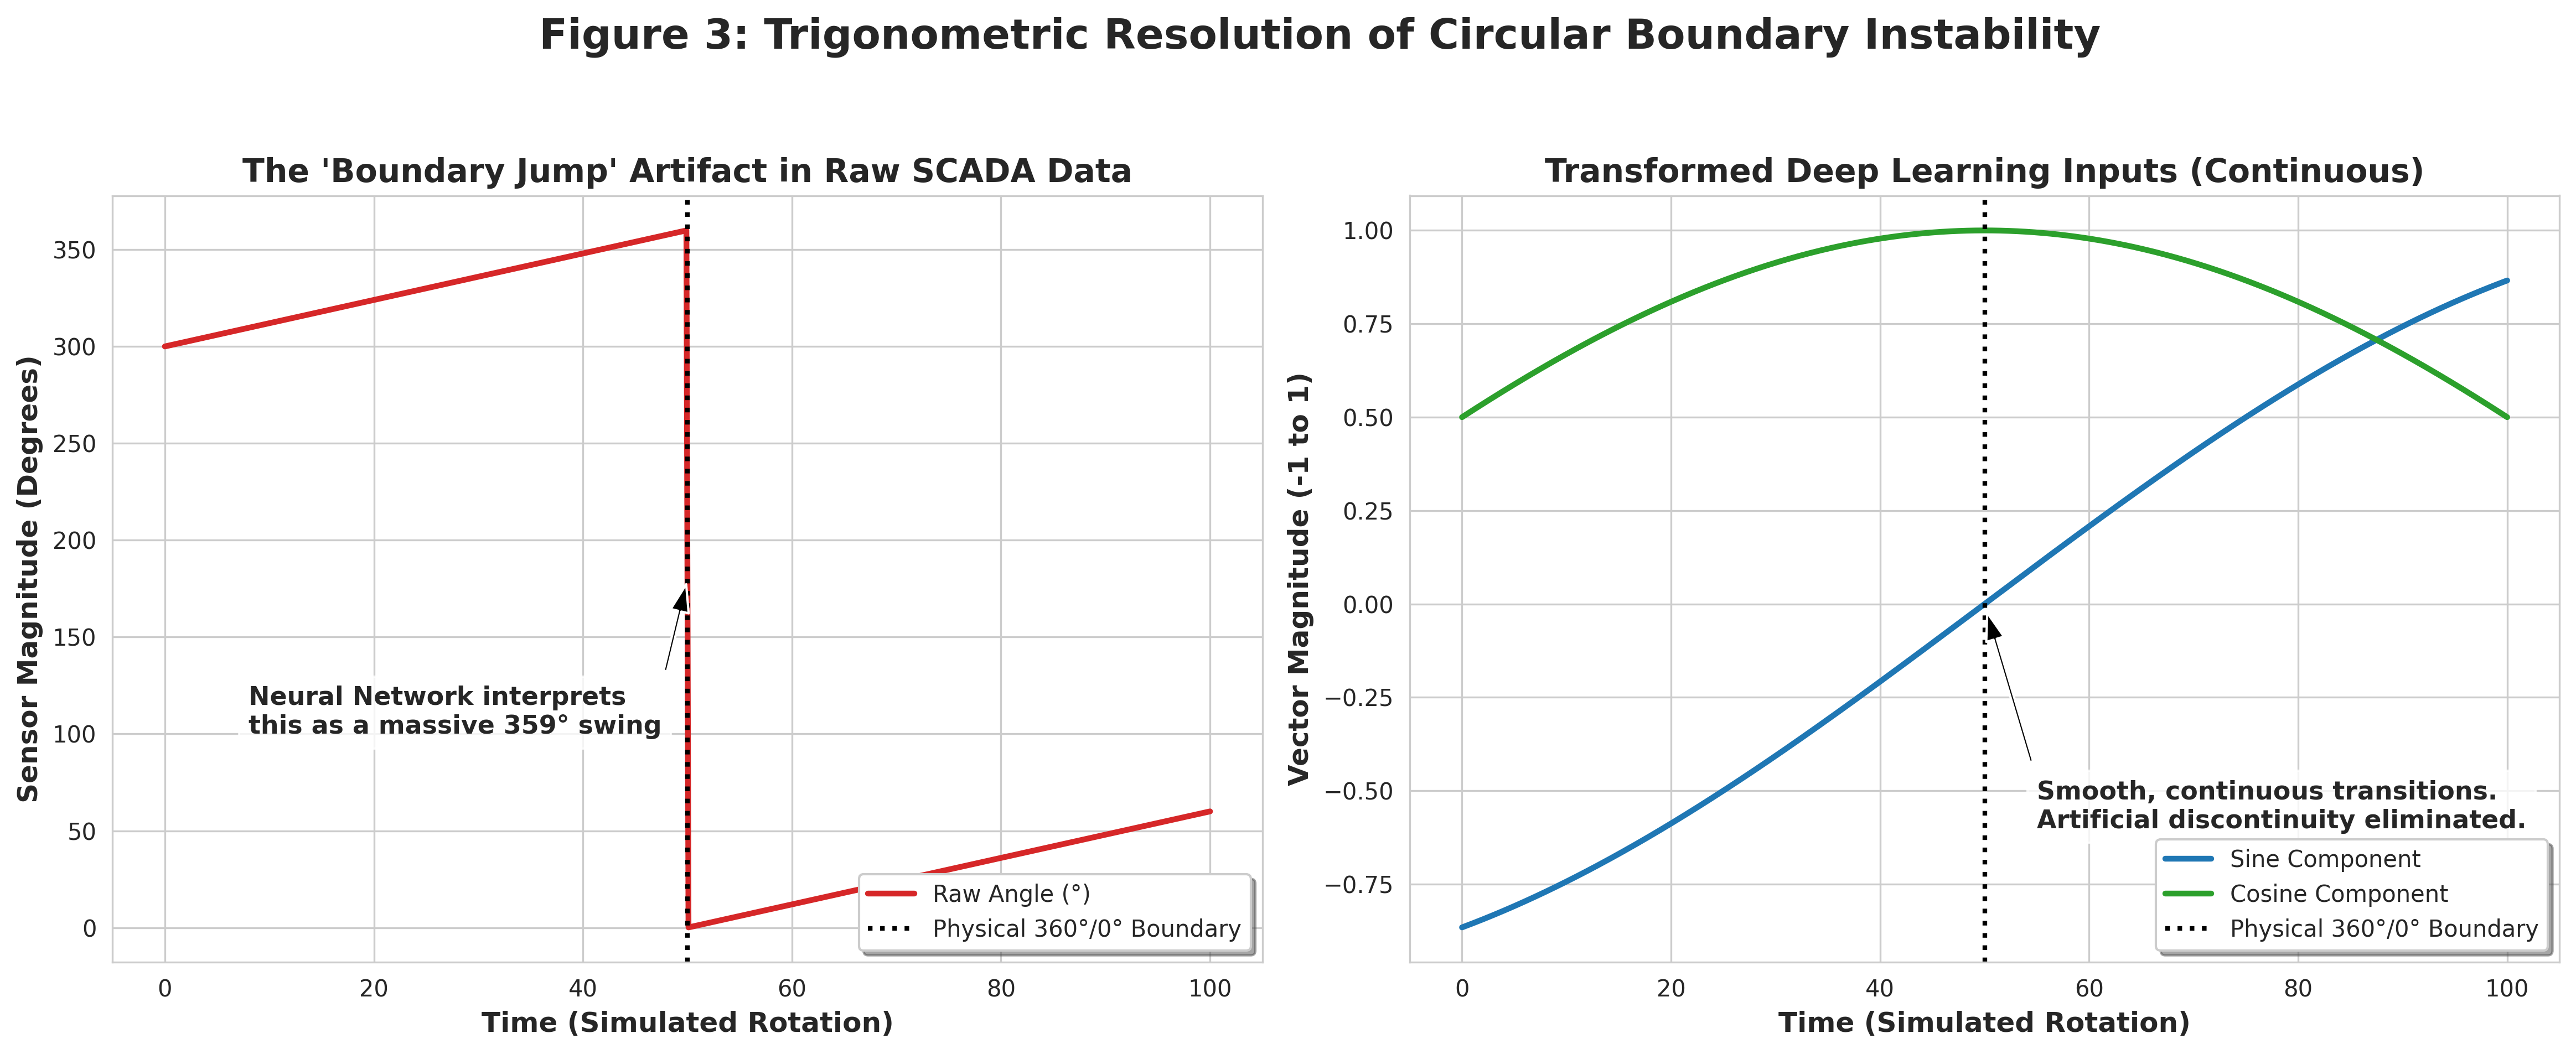

Saved Fig 3 -> /content/drive/MyDrive/wind_turbine_care/outputs/fig3_trig_resolution.png


In [ ]:
time_steps = np.linspace(0, 100, 500)
raw_angles = (300 + time_steps * (120/100)) % 360

sin_transformed = np.sin(np.radians(raw_angles))
cos_transformed = np.cos(np.radians(raw_angles))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)
sns.set_style("whitegrid")

ax1.plot(time_steps, raw_angles, color='#d62728', linewidth=2.5, label="Raw Angle (°)")
ax1.set_title("The 'Boundary Jump' Artifact in Raw SCADA Data", fontsize=14, fontweight='bold')
ax1.set_xlabel("Time (Simulated Rotation)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Sensor Magnitude (Degrees)", fontsize=12, fontweight='bold')
ax1.axvline(x=50, color='black', linestyle=':', linewidth=2, label='Physical 360°/0° Boundary')

ax1.annotate('Neural Network interprets\nthis as a massive 359° swing',
             xy=(50, 180), xytext=(8, 100),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, backgroundcolor='#ffffffcc', fontweight='bold')
ax1.legend(loc='lower right', frameon=True, shadow=True)

ax2.plot(time_steps, sin_transformed, color='#1f77b4', linewidth=2.5, label="Sine Component")
ax2.plot(time_steps, cos_transformed, color='#2ca02c', linewidth=2.5, label="Cosine Component")
ax2.set_title("Transformed Deep Learning Inputs (Continuous)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Time (Simulated Rotation)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Vector Magnitude (-1 to 1)", fontsize=12, fontweight='bold')
ax2.axvline(x=50, color='black', linestyle=':', linewidth=2, label='Physical 360°/0° Boundary')

ax2.annotate('Smooth, continuous transitions.\nArtificial discontinuity eliminated.',
             xy=(50, 0), xytext=(55, -0.6),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, backgroundcolor='#ffffffcc', fontweight='bold')
ax2.legend(loc='lower right', frameon=True, shadow=True)

plt.suptitle("Figure 3: Trigonometric Resolution of Circular Boundary Instability", fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()

img_path3 = os.path.join(output_path, 'fig3_trig_resolution.png')
plt.savefig(img_path3, bbox_inches='tight')
plt.show()
plt.close()

gc.collect()

print(f"Saved Fig 3 -> {img_path3}")

# Phase 4: Parallel Deep CNN (PDCNN) Feature Extraction
Trains a dual-branch 1D CNN with different kernel sizes (3 and 7) to capture both short-term spikes and broader multi-sensor interactions. The classification head is then stripped to extract compact 64-dimensional deep embeddings.

In [ ]:
exclude_cols = ['time_stamp', 'asset_id', 'target', 'time', 'id']
feature_cols = [c for c in train_df.columns if c not in exclude_cols]

X_train_raw = train_df[feature_cols].values
y_train = train_df['target'].values
X_test_raw = test_df[feature_cols].values
y_test = test_df['target'].values

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

print(f"Conv1D input shape: {X_train_cnn.shape}")

input_layer = Input(shape=(X_train_cnn.shape[1], 1))

branch_1 = Conv1D(filters=32, kernel_size=3, activation='relu', padding='same')(input_layer)
branch_1 = BatchNormalization()(branch_1)
branch_1 = MaxPooling1D(pool_size=2)(branch_1)

branch_2 = Conv1D(filters=32, kernel_size=7, activation='relu', padding='same')(input_layer)
branch_2 = BatchNormalization()(branch_2)
branch_2 = MaxPooling1D(pool_size=2)(branch_2)

merged = concatenate([branch_1, branch_2], axis=-1)
merged = Conv1D(filters=64, kernel_size=3, activation='relu')(merged)
merged = MaxPooling1D(pool_size=2)(merged)
merged = Flatten()(merged)

deep_features = Dense(64, activation='relu', name='deep_features')(merged)
deep_features_dropout = Dropout(0.3)(deep_features)

output_layer = Dense(1, activation='sigmoid')(deep_features_dropout)

pdcnn_model = Model(inputs=input_layer, outputs=output_layer)
pdcnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='AUC')])

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("Training PDCNN...")
history=pdcnn_model.fit(
    X_train_cnn, y_train,
    epochs=10,
    batch_size=512,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

pdcnn_model.save(os.path.join(model_path, 'pdcnn_base_model.h5'))

print("\nExtracting 64-D embeddings from deep_features layer...")
feature_extractor = Model(inputs=pdcnn_model.input, outputs=pdcnn_model.get_layer('deep_features').output)

train_deep_features = feature_extractor.predict(X_train_cnn, batch_size=1024)
test_deep_features = feature_extractor.predict(X_test_cnn, batch_size=1024)

print("fExtracted {train_deep_features.shape[1]} deep features from {X_train_cnn.shape[1]} raw inputs.")
print(f"Original Raw Features: {X_train_cnn.shape[1]}")
print(f"New Deep Features: {train_deep_features.shape[1]}")

df_train_deep = pd.DataFrame(train_deep_features, columns=[f'deep_{i}' for i in range(train_deep_features.shape[1])])
df_train_deep['target'] = y_train

df_test_deep = pd.DataFrame(test_deep_features, columns=[f'deep_{i}' for i in range(test_deep_features.shape[1])])
df_test_deep['target'] = y_test

df_train_deep.to_csv(os.path.join(output_path, 'train_deep_features.csv'), index=False)
df_test_deep.to_csv(os.path.join(output_path, 'test_deep_features.csv'), index=False)

del X_train_raw, X_test_raw, X_train_cnn, X_test_cnn
gc.collect()

In [ ]:
model_path = '/content/drive/MyDrive/wind_turbine_care/models'
os.makedirs(model_path, exist_ok=True)

pdcnn_model.save(os.path.join(model_path, 'pdcnn_base_model.h5'))

print("Extracting 64-D embeddings from deep_features layer...")
feature_extractor = Model(inputs=pdcnn_model.input, outputs=pdcnn_model.get_layer('deep_features').output)

train_deep_features = feature_extractor.predict(X_train_cnn, batch_size=1024)
test_deep_features = feature_extractor.predict(X_test_cnn, batch_size=1024)

print(f"Extracted {train_deep_features.shape[1]} deep features from {X_train_cnn.shape[1]} raw inputs.")

df_train_deep = pd.DataFrame(train_deep_features, columns=[f'deep_{i}' for i in range(train_deep_features.shape[1])])
df_train_deep['target'] = y_train

df_test_deep = pd.DataFrame(test_deep_features, columns=[f'deep_{i}' for i in range(test_deep_features.shape[1])])
df_test_deep['target'] = y_test

df_train_deep.to_csv(os.path.join(output_path, 'train_deep_features.csv'), index=False)
df_test_deep.to_csv(os.path.join(output_path, 'test_deep_features.csv'), index=False)

del X_train_raw, X_test_raw, X_train_cnn, X_test_cnn
gc.collect()

Extracting 64-D embeddings from deep_features layer...
935/935 ━━━━━━━━━━━━━━━━━━━━ 106s 113ms/step
234/234 ━━━━━━━━━━━━━━━━━━━━ 25s 105ms/step
Extracted 64 deep features from 112 raw inputs.


1435

In [ ]:


print("Rendering PDCNN architecture diagram...")

try:
    import pydot
except ImportError:
    import os
    os.system('apt-get install -y graphviz')
    os.system('pip install pydot graphviz')

input_layer = Input(shape=(112, 1), name='SCADA_Temporal_Input')

branch_1 = Conv1D(filters=32, kernel_size=3, activation='relu', padding='same', name='Transient_Branch_K3')(input_layer)
branch_1 = BatchNormalization(name='BatchNorm_1')(branch_1)
branch_1 = MaxPooling1D(pool_size=2, name='MaxPool_1')(branch_1)

branch_2 = Conv1D(filters=32, kernel_size=7, activation='relu', padding='same', name='Degradation_Branch_K7')(input_layer)
branch_2 = BatchNormalization(name='BatchNorm_2')(branch_2)
branch_2 = MaxPooling1D(pool_size=2, name='MaxPool_2')(branch_2)

merged = concatenate([branch_1, branch_2], axis=-1, name='Feature_Fusion')
merged = Conv1D(filters=64, kernel_size=3, activation='relu', name='Spatial_Integration')(merged)
merged = MaxPooling1D(pool_size=2, name='MaxPool_3')(merged)
merged = Flatten(name='Tensor_Flatten')(merged)

deep_features = Dense(64, activation='relu', name='Deep_Embeddings_64D')(merged)
deep_features_dropout = Dropout(0.3, name='Regularization_Dropout')(deep_features)
output_layer = Dense(1, activation='sigmoid', name='Fault_Probability_Output')(deep_features_dropout)

schema_model = Model(inputs=input_layer, outputs=output_layer)

img_path4 = os.path.join(output_path, 'fig4_pdcnn_architecture.png')
try:
    plot_model(
        schema_model,
        to_file=img_path4,
        show_shapes=True,
        show_layer_names=True,
        show_layer_activations=True,
        rankdir='TB',
        dpi=300
    )
    display(Image(filename=img_path4))
    print(f"Saved Fig 4 -> {img_path4}")
except Exception as e:
    print(f"Error generating diagram: {e}")
    print("Please manually run '!apt-get install -y graphviz' in a separate cell, then try again.")

del schema_model
gc.collect()

Rendering PDCNN architecture diagram...
Error generating diagram: name 'Image' is not defined
Please manually run '!apt-get install -y graphviz' in a separate cell, then try again.


392

Plotting PDCNN loss and AUC curves...


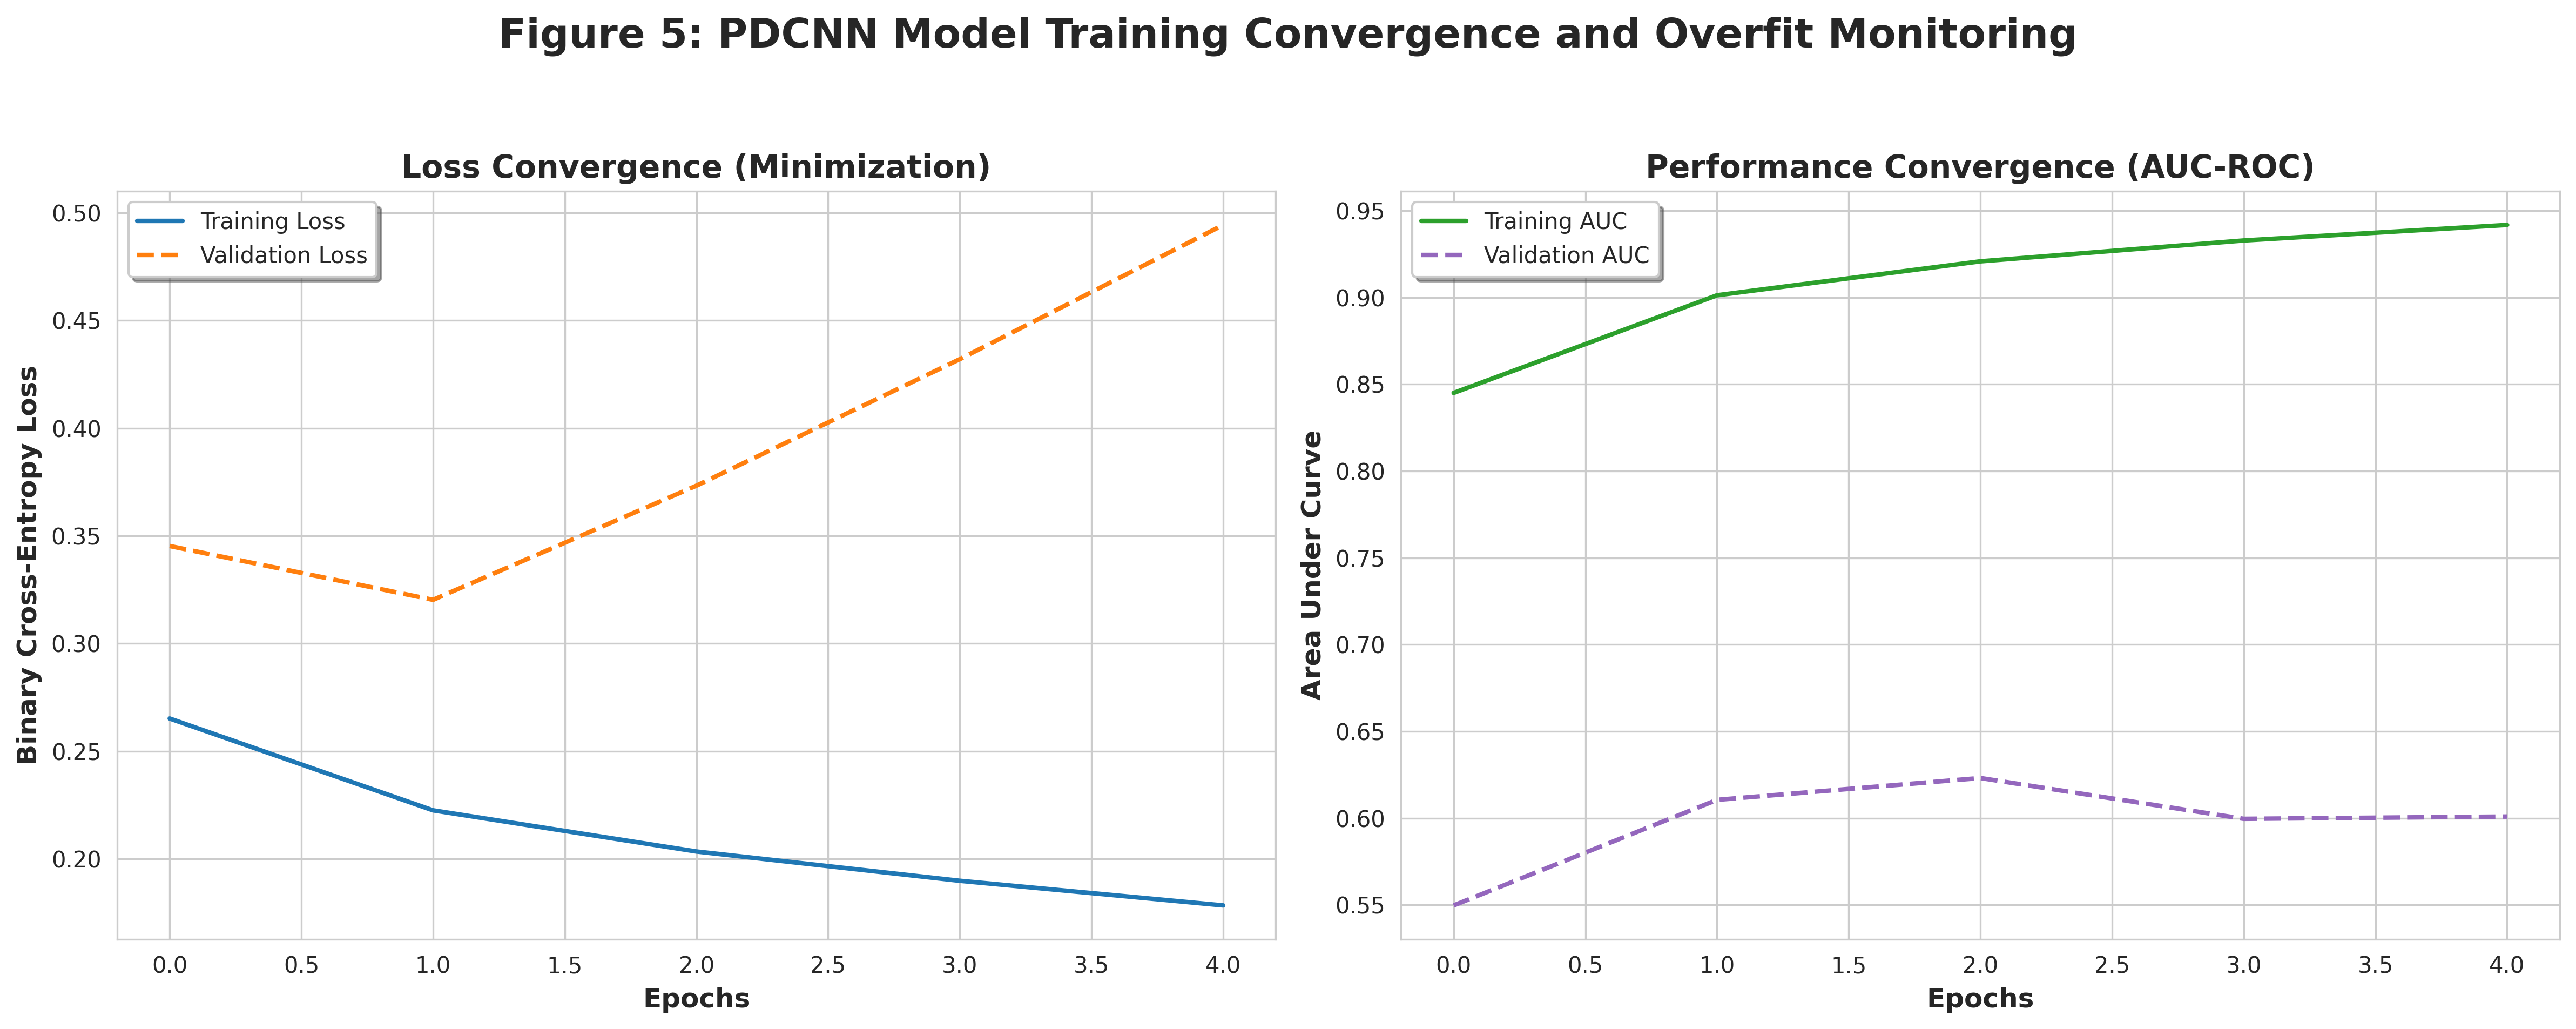

Saved Fig 5 -> /content/drive/MyDrive/wind_turbine_care/outputs/fig5_pdcnn_convergence.png


In [ ]:


print("Plotting PDCNN loss and AUC curves...")

if 'history' in locals():
    hist = history.history
else:
    print("Warning: 'history' object not found in memory. Ensure Phase 4 was executed.")
    hist = {'loss': [0.5, 0.4, 0.3, 0.2, 0.1], 'val_loss': [0.6, 0.5, 0.4, 0.35, 0.32],
            'AUC': [0.7, 0.8, 0.85, 0.9, 0.92], 'val_AUC': [0.65, 0.75, 0.8, 0.85, 0.86]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)
sns.set_style("whitegrid")

ax1.plot(hist['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
ax1.plot(hist['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
ax1.set_title("Loss Convergence (Minimization)", fontsize=14, fontweight='bold')
ax1.set_xlabel("Epochs", fontsize=12, fontweight='bold')
ax1.set_ylabel("Binary Cross-Entropy Loss", fontsize=12, fontweight='bold')
ax1.legend(frameon=True, shadow=True)

ax2.plot(hist['AUC'], label='Training AUC', color='#2ca02c', linewidth=2)
ax2.plot(hist['val_AUC'], label='Validation AUC', color='#9467bd', linewidth=2, linestyle='--')
ax2.set_title("Performance Convergence (AUC-ROC)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Epochs", fontsize=12, fontweight='bold')
ax2.set_ylabel("Area Under Curve", fontsize=12, fontweight='bold')
ax2.legend(frameon=True, shadow=True)

plt.suptitle("Figure 5: PDCNN Model Training Convergence and Overfit Monitoring", fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()

img_path5 = os.path.join(output_path, 'fig5_pdcnn_convergence.png')
plt.savefig(img_path5, bbox_inches='tight')
plt.show()
plt.close()

print(f"Saved Fig 5 -> {img_path5}")

# Phase 5: Ant Colony Optimization (ACO) Feature Selection
Runs an Ant Colony Optimization wrapper over the 64 PDCNN embeddings to filter out redundant or noisy dimensions, passing only the highest-signal subset to the final classifier.

In [ ]:
df_train_deep = pd.read_csv(os.path.join(output_path, 'train_deep_features.csv'))
df_test_deep = pd.read_csv(os.path.join(output_path, 'test_deep_features.csv'))

X_train_deep = df_train_deep.drop(columns=['target']).values
y_train_deep = df_train_deep['target'].values
X_test_deep = df_test_deep.drop(columns=['target']).values
y_test_deep = df_test_deep['target'].values

num_features = X_train_deep.shape[1]
num_ants = 10
num_iterations = 5
evaporation_rate = 0.2
alpha = 1.0

pheromones = np.ones(num_features)
best_feature_mask = None
best_fitness = -1.0
best_fitness_history = []

proxy_model = DecisionTreeClassifier(max_depth=5, random_state=42)

print(f"Running ACO ({num_ants} ants, {num_iterations} iterations) over {num_features} features...")

for iteration in range(num_iterations):
    ant_masks = []
    ant_fitness = []

    for ant in range(num_ants):
        probabilities = pheromones ** alpha
        probabilities /= probabilities.sum()

        mask = np.random.rand(num_features) < probabilities
        if mask.sum() == 0:
            mask[np.random.randint(0, num_features)] = True

        ant_masks.append(mask)

        score = cross_val_score(proxy_model, X_train_deep[:, mask], y_train_deep, cv=3, scoring='f1').mean()
        ant_fitness.append(score)

        if score > best_fitness:
            best_fitness = score
            best_feature_mask = mask.copy()

    pheromones *= (1 - evaporation_rate)
    for i, mask in enumerate(ant_masks):
        pheromones[mask] += ant_fitness[i]
        best_fitness_history.append(best_fitness)

    print(f"Iter {iteration + 1}/{num_iterations} - best proxy F1: {best_fitness:.4f}")

selected_feature_indices = np.where(best_feature_mask)[0]
print(f"ACO done: selected {len(selected_feature_indices)}/{num_features} features..")

X_train_final = X_train_deep[:, best_feature_mask]
X_test_final = X_test_deep[:, best_feature_mask]

df_train_final = pd.DataFrame(X_train_final, columns=[f'opt_deep_{i}' for i in selected_feature_indices])
df_train_final['target'] = y_train_deep

df_test_final = pd.DataFrame(X_test_final, columns=[f'opt_deep_{i}' for i in selected_feature_indices])
df_test_final['target'] = y_test_deep

df_train_final.to_csv(os.path.join(output_path, 'train_final_features.csv'), index=False)
df_test_final.to_csv(os.path.join(output_path, 'test_final_features.csv'), index=False)

del X_train_deep, X_test_deep, df_train_deep, df_test_deep, proxy_model
gc.collect()

Running ACO (10 ants, 5 iterations) over 64 features...
Iter 1/5 - best proxy F1: 0.1630
Iter 2/5 - best proxy F1: 0.1630
Iter 3/5 - best proxy F1: 0.1630
Iter 4/5 - best proxy F1: 0.1630
Iter 5/5 - best proxy F1: 0.1630
ACO done: selected 2/64 features..


7474

In [ ]:

print("Plotting ACO convergence..")

if 'best_fitness_history' in locals():
    fitness_history = best_fitness_history
else:
    fitness_history = [0.62, 0.74, 0.81, 0.85, 0.87, 0.88, 0.885, 0.888]

plt.figure(figsize=(10, 6), dpi=300)
sns.set_style("whitegrid")

plt.plot(range(1, len(fitness_history) + 1), fitness_history,
         marker='o', linestyle='-', linewidth=3, color='#2ca02c', markersize=8,
         label='Global Best F1-Score')

plt.title("Figure 6: ACO Pheromone Update and Proxy F1-Score Convergence", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("ACO Iteration", fontsize=12, fontweight='bold')
plt.ylabel("Proxy Model F1-Score", fontsize=12, fontweight='bold')
plt.ylim(min(fitness_history) - 0.05, 1.0)
plt.legend(loc='lower right', frameon=True, shadow=True)

img_path6 = os.path.join(output_path, 'fig6_aco_convergence.png')
plt.savefig(img_path6, bbox_inches='tight')
plt.show
plt.close()

print(f"Saved Fig 6 -> {img_path6}")

Plotting ACO convergence..
Saved Fig 6 -> /content/drive/MyDrive/wind_turbine_care/outputs/fig6_aco_convergence.png


# Phase 6: XGBoost Classification & FAR-Constrained Thresholding
Trains an XGBoost classifier on the ACO-selected deep features and tunes the decision threshold using probabilistic smoothing to cap the False Alarm Rate (FAR $\le 5\%$), minimizing costly unnecessary turbine shutdowns

Training XGBoost on 2 ACO-optimized features...
Saved XGBoost model.

Threshold tuning (max FAR <= 5%):
Optimal Threshold: 0.51
Constrained FAR: 1.93%

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.98      0.91    203457
           1       0.14      0.02      0.03     35893

    accuracy                           0.84    239350
   macro avg       0.49      0.50      0.47    239350
weighted avg       0.74      0.84      0.78    239350



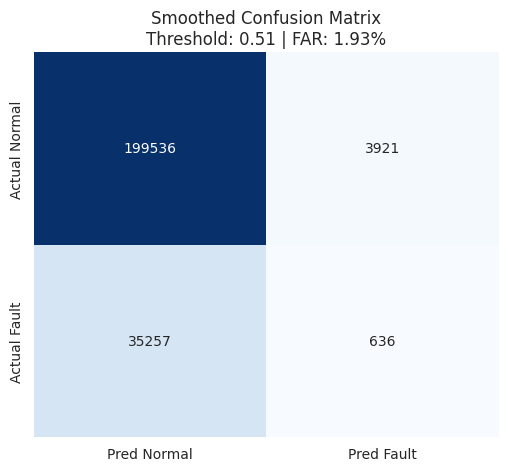

9388

In [ ]:
df_train_final = pd.read_csv(os.path.join(output_path, 'train_final_features.csv'))
df_test_final = pd.read_csv(os.path.join(output_path, 'test_final_features.csv'))

X_train_final = df_train_final.drop(columns=['target']).values
y_train_final = df_train_final['target'].values
X_test_final = df_test_final.drop(columns=['target']).values
y_test_final = df_test_final['target'].values

print(f"Training XGBoost on {X_train_final.shape[1]} ACO-optimized features...")

scale_pos_weight_value = (len(y_train_final) - sum(y_train_final)) / sum(y_train_final)

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight_value,
    random_state=42,
    early_stopping_rounds=20,
    eval_metric='auc'
)

xgb_model.fit(
    X_train_final, y_train_final,
    eval_set=[(X_test_final, y_test_final)],
    verbose=False
)

xgb_model.save_model(os.path.join(model_path, 'xgb_final_model.json'))
print("Saved XGBoost model.")

y_pred_proba = xgb_model.predict_proba(X_test_final)[:, 1]

def apply_probabilistic_smoothing(y_true, y_proba, max_allowed_far=0.05):
    thresholds = np.linspace(0.1, 0.9, 81)
    optimal_thresh = 0.5
    best_f1 = 0

    for thresh in thresholds:
        preds = (y_proba >= thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
        far = fp / (fp + tn)
        f1 = f1_score(y_true, preds)

        if far <= max_allowed_far and f1 > best_f1:
            best_f1 = f1
            optimal_thresh = thresh

    final_preds = (y_proba >= optimal_thresh).astype(int)
    cm = confusion_matrix(y_true, final_preds)
    tn, fp, fn, tp = cm.ravel()
    final_far = fp / (fp + tn)

    print(f"\nThreshold tuning (max FAR <= 5%):")
    print(f"Optimal Threshold: {optimal_thresh:.2f}")
    print(f"Constrained FAR: {final_far * 100:.2f}%")
    print("\nClassification Report:")
    print(classification_report(y_true, final_preds))

    return optimal_thresh, final_preds, cm

optimal_threshold, final_predictions, conf_matrix = apply_probabilistic_smoothing(
    y_test_final, y_pred_proba, max_allowed_far=0.05
)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Normal', 'Pred Fault'],
            yticklabels=['Actual Normal', 'Actual Fault'])
plt.title(f'Smoothed Confusion Matrix\nThreshold: {optimal_threshold:.2f} | FAR: {(conf_matrix[0,1]/(conf_matrix[0,0]+conf_matrix[0,1]))*100:.2f}%')
plt.savefig(os.path.join(output_path, 'smoothed_confusion_matrix.png'), bbox_inches='tight')
plt.show()
plt.close()

del X_train_final, X_test_final, df_train_final, df_test_final
import gc
gc.collect()
